# Feature sifting on a corrupted-signal problem with sign flips

**Problem.** `phd/jax_core/tasks/feature_sifting.py`. The target sums `N_TARGET_FEATURES` signals,
each uniform on $[-1, 1]$ with a weight of $\pm 1$, under $N(0, 1)$ observation noise, and the
learner observes `N_LEARNER_FEATURES` candidate slots. Each candidate is a corrupted view of a
random signal, $(1 - c)\,\text{signal} + c\,\text{noise}$, where the noise is an independent
uniform draw over the same range and the noise coefficient $c$ is drawn uniformly on $[0, 1]$.
Every `FLIP_PERIOD` steps, one target weight (chosen at random) flips sign, so a learner's weight
on that signal has to cross zero to follow it.

Where the clean-or-noise problem makes a candidate either perfect or worthless, here nearly every
candidate carries *some* signal, so nearly every weight has a non-zero ideal value. A test that
only asks whether a weight is dead stops firing once the pool is full. Getting further means
giving up a useful feature in the hope of drawing a better one, which is what a competitive
method has to decide.

**Learner.** The same as in `clean_or_noise/clean_or_noise.ipynb`: one linear predictor over
the slots, plus a bias, every weight starting at zero under Autostep. Pruning a slot **redraws the
feature behind it** and resets the slot to its starting state.

**Methods.** Autostep never prunes, and shows what the initial pool is worth. Autostep + CI cuts
a slot whose weight is within one standard deviation of zero, the standard deviation being that of
a dead weight of the same age. Autostep + utility threshold replaces that fixed one with a bar `q`
that moves: it rises when maturing slots clear it, and falls back toward one while slots are still
warming up. Autostep + CI on $|w| + |h|$ (proposed) runs the CI test on $|w| + |h|$, $h$ being
Autostep's trace, against the bound a dead weight's $|w| + |h|$ stays under 68% of the time; a
useful weight crossing zero keeps a large $|h|$ while it crosses. Autostep + utility threshold on
$|w| + |h|$ (proposed) moves the bar on that utility instead.

In [ ]:
import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
import seaborn as sns

from phd.jax_core.optimizers.idbd import optax_idbd, IDBDState
from phd.jax_core.tasks.feature_sifting import FeatureSiftingTask
from phd.jax_core.utils import stack_pytrees, tree_replace
from phd.research_utils.analysis.analysis_utils import get_color_palette

sns.set_theme('notebook', 'white')
%matplotlib inline

In [ ]:
# --- Problem ---
N_TARGET_FEATURES = 10               # true signals the target function sums
N_LEARNER_FEATURES = 10              # candidate slots the learner observes
NOISE_STD = 1.0                      # observation noise on the target
FLIP_PERIOD = 10_000                 # steps between sign flips, each of one target weight chosen at random

# --- Optimizers ---
INIT_STEP_SIZE = 1e-10               # Autostep's starting step-size for every slot
META_STEP_SIZE = 0.02
BAND_TRACE_HORIZON = 1_000           # EMA horizon for E[delta^2] (both CI methods)
BAR_HORIZON = 100_000                # how slowly warming-up slots pull the utility threshold down

# --- Training and recording ---
NUM_STEPS = 1_000_000
N_SEEDS = 30                         # vmapped into one scan; scan width is nearly free
N_SNAPSHOTS = 200                    # recording points per run
BASE_SEED = 0

# --- Derived ---
N_OUTPUTS = 1                        # one target, but the (output, slot) grid shape is kept
N_SLOTS = N_LEARNER_FEATURES + 1     # one weight per candidate, plus a bias column
INPUT_VAR = 1 / 3                    # variance of a uniform [-1, 1] input, signal or noise
IRREDUCIBLE_MSE = NOISE_STD ** 2     # MSE with an exact copy of every signal

## Learners

Each method is a self-contained `eqx.Module` with `init()` and `step(inputs, y)`, and carries the
`prune_mask` the task reads to redraw candidates. `inputs` is the `(n_outputs, n_learner_features)`
slot grid, padded here with the bias column.

In [ ]:
def slot_inputs(inputs):
    """Pad the slot grid with the bias column: a constant-1 input, never a candidate.

    Keeping the bias inside the weight matrix is what Autostep's per-output-row normalizer
    needs — it does not support a separate bias vector.
    """
    return jnp.concatenate([inputs, jnp.ones((N_OUTPUTS, 1))], axis=1)


def linear_loss_and_grads(w, x, y):
    """Squared error, and the LMS gradient `delta * x`.

    That is the exact gradient up to the constant factor 2, which is folded into the step-size.
    """
    error = jnp.sum(w * x, axis=-1) - y
    return jnp.sum(error ** 2), error[:, None] * x


def init_autostep(cls, **extra):
    """Build an Autostep-based learner: zero weights, a fresh optimizer state, nothing pruned."""
    optimizer = optax_idbd(init_lr=INIT_STEP_SIZE, meta_lr=META_STEP_SIZE, autostep=True)
    w = jnp.zeros((N_OUTPUTS, N_SLOTS))
    return cls(optimizer=optimizer, w=w, opt_state=optimizer.init(w),
               prune_mask=jnp.zeros((N_OUTPUTS, N_LEARNER_FEATURES), dtype=bool), **extra)


def reset_pruned(w, opt_state, prune_mask):
    """Return every slot the learner just cut to its starting state: zero weight, `INIT_STEP_SIZE`,
    no traces. The task swaps the new candidate in at the top of the next step."""
    pruned = jnp.pad(prune_mask, ((0, 0), (0, 1)))     # the bias column is never pruned
    return jnp.where(pruned, 0.0, w), IDBDState(
        init_beta=opt_state.init_beta,
        beta=jnp.where(pruned, opt_state.init_beta, opt_state.beta),
        h=jnp.where(pruned, 0.0, opt_state.h),
        v=jnp.where(pruned, 0.0, opt_state.v),
    )

In [ ]:
class Autostep(eqx.Module):
    """Autostep (IDBD) on the initial pool: a step-size per slot, but no pruning."""
    optimizer: optax.GradientTransformation = eqx.field(static=True)
    w: jax.Array
    opt_state: optax.OptState
    prune_mask: jax.Array

    @classmethod
    def init(cls):
        return init_autostep(cls)

    def step(self, inputs, y):
        x = slot_inputs(inputs)
        loss, grads = linear_loss_and_grads(self.w, x, y)
        # Autostep consumes the loss gradient and the prediction gradient (= x, this being a
        # linear model), and normalizes each output's row of step-sizes on its own.
        updates, opt_state = self.optimizer.update((grads, x), self.opt_state, self.w)
        return tree_replace(self, w=self.w + updates, opt_state=opt_state), loss

In [ ]:
class AutostepCI(eqx.Module):
    """Autostep + CI pruning: a slot is cut once its weight is within `q` standard deviations of
    zero, where the standard deviation is that of a dead weight **of the same age**,

        s(t) = sqrt(alpha * E[delta^2] / 2 * m_t),    m_t = 1 - prod_k (1 - alpha_k x_k^2)^2.

    The maturity `m_t` climbs from 0 at birth to 1, so the band starts at zero width alongside the
    weight and widens at the rate a dead weight wanders. The weight is tested against the maturity
    it had *before* this step, so a candidate always survives its first step. The maturity is kept
    as `log(1 - m_t)`, because the direct form rounds to zero in float32 at small step-sizes.

    With `adaptive=False` the bar stays at `q = 1`, the non-competitive test.

    With `adaptive=True`, `q` is a utility threshold on `z = |w| / s(t)`, one per output, that moves

    - **up** when slots clear it: every slot pulls `q` toward its own `z`, weighted by the maturity
      it gained this step, so each candidate casts one vote in total, spread over its warm-up. A
      slot that falls below `q` is cut, so nearly all of the vote comes from slots above it.
    - **down** while slots are still warming up: each pulls `q` toward the floor of 1 at a rate of
      `(1 - m_t) / BAR_HORIZON`, so a pool whose new candidates keep failing lowers its bar.

    With `trace=True`, the utility is `|w| + |h|`, `h` being Autostep's trace, in place of `|w|`
    (in the test and in `z`), and the band is the bound a dead weight's `|w| + |h|` stays under 68% of the time,
    `s(t) * (1.61 + 0.39 exp(-1.5 tau))` with age `tau = -log(1 - m_t) / 2` (within 2%). A useful
    weight that has to cross zero keeps a large `|h|` while it crosses.
    """
    optimizer: optax.GradientTransformation = eqx.field(static=True)
    adaptive: bool = eqx.field(static=True)
    trace: bool = eqx.field(static=True)
    w: jax.Array
    opt_state: optax.OptState
    v: jax.Array          # (n_outputs, 1) EMA of the output's squared residual
    v_weight: jax.Array   # accumulated EMA gain, so `v` reads unbiased from step 1
    log_imm: jax.Array    # (n_outputs, n_slots) log(1 - maturity): 0 at birth, -inf once mature
    q: jax.Array          # (n_outputs, 1) the bar, in standard deviations of a dead weight
    prune_mask: jax.Array

    @classmethod
    def init(cls, adaptive=False, trace=False):
        return init_autostep(cls, adaptive=adaptive, trace=trace, v=jnp.zeros((N_OUTPUTS, 1)),
                             v_weight=jnp.zeros(()), log_imm=jnp.zeros((N_OUTPUTS, N_SLOTS)),
                             q=jnp.ones((N_OUTPUTS, 1)))

    def step(self, inputs, y):
        x = slot_inputs(inputs)
        error = jnp.sum(self.w * x, axis=-1) - y
        loss, grads = jnp.sum(error ** 2), error[:, None] * x
        updates, opt_state = self.optimizer.update((grads, x), self.opt_state, self.w)
        w = self.w + updates

        # E[delta^2] belongs to the output's residual, not to any one slot, so a redraw leaves it
        # alone; `v_weight` de-biases it away from its zero start.
        gain = 1.0 / BAND_TRACE_HORIZON
        v = self.v + gain * (error[:, None] ** 2 - self.v)
        v_weight = self.v_weight + gain * (1.0 - self.v_weight)

        # The band the *pre-update* age calls for, then the age advances.
        alpha = jnp.exp(opt_state.beta)
        utility = jnp.abs(w) + jnp.abs(opt_state.h) if self.trace else jnp.abs(w)
        factor = lambda log_imm: 1.61 + 0.39 * jnp.exp(0.75 * log_imm) if self.trace else 1.0  # exp(-1.5 tau)
        band = jnp.sqrt(alpha * (v / v_weight) / 2.0 * -jnp.expm1(self.log_imm)) * factor(self.log_imm)
        d_log_imm = 2.0 * jnp.log1p(-alpha * x ** 2)
        log_imm = self.log_imm + d_log_imm

        q = self.q
        if self.adaptive:
            band_new = jnp.sqrt(alpha * (v / v_weight) / 2.0 * -jnp.expm1(log_imm)) * factor(log_imm)
            z = jnp.where(band_new > 0, utility / band_new, 0.0)
            gained = jnp.exp(self.log_imm) * -jnp.expm1(d_log_imm)   # m_new - m_old
            warming = jnp.exp(log_imm) / BAR_HORIZON                 # (1 - m_new) / BAR_HORIZON
            pulls = gained * (z - q) + warming * (1.0 - q)
            q = jnp.maximum(q + jnp.sum(pulls[:, :N_LEARNER_FEATURES], axis=-1, keepdims=True), 1.0)

        prune_mask = (utility < self.q * band)[:, :N_LEARNER_FEATURES]
        w, opt_state = reset_pruned(w, opt_state, prune_mask)
        # A redrawn slot restarts its warm-up, so it meets a zero-width band on its first step.
        log_imm = jnp.where(jnp.pad(prune_mask, ((0, 0), (0, 1))), 0.0, log_imm)
        return tree_replace(self, w=w, opt_state=opt_state, v=v, v_weight=v_weight,
                            log_imm=log_imm, q=q, prune_mask=prune_mask), loss

## Training

In [ ]:
def make_task(seed):
    return FeatureSiftingTask(
        n_target_features=N_TARGET_FEATURES, n_learner_features=N_LEARNER_FEATURES,
        target_noise_std=NOISE_STD, flip_period=FLIP_PERIOD, key=jax.random.PRNGKey(seed))


def signal_recovered(task):
    """Fraction of each signal's variance that the best linear readout of the pool recovers.

    A slot with noise coefficient c sees its signal at an SNR of ((1 - c) / c)^2, the signal and
    its noise having the same variance. The noise is independent across slots, so the SNRs of the
    slots on one signal add, and a total SNR of R recovers R / (1 + R) of the signal.
    """
    c = jnp.maximum(task.noise_coefficients, 1e-12)     # c = 0 is an exact copy
    snr = jnp.zeros(N_TARGET_FEATURES).at[task.learner_feature_idxs].add(((1 - c) / c) ** 2)
    return snr / (1 + snr)


def train(learner, task, block_len):
    """Online training in `N_SNAPSHOTS` blocks of `block_len` steps, one summary row per block."""
    def one_step(carry, _):
        learner, task = carry
        task, (inputs, y) = task.step(learner.prune_mask[0])   # the task redraws what was cut
        learner, loss = learner.step(inputs[None, :], y)
        q = learner.q[0, 0] if hasattr(learner, 'q') else jnp.nan   # Autostep has no bar
        return (learner, task), (loss, jnp.sum(learner.prune_mask), q)

    def block(carry, _):
        carry, (losses, n_cut, q) = jax.lax.scan(one_step, carry, length=block_len)
        task = carry[1]
        return carry, (losses.mean(), n_cut.mean(), q.mean(), task.noise_coefficients.mean(),
                       signal_recovered(task))

    _, out = jax.lax.scan(block, (learner, task), length=N_SNAPSHOTS)
    return out


def run(make_learner):
    """Train `N_SEEDS` independent runs — a fresh teacher and pool each — in one vmapped scan."""
    block_len = NUM_STEPS // N_SNAPSHOTS
    tasks = stack_pytrees([make_task(BASE_SEED + s) for s in range(N_SEEDS)])
    keys = ('mse', 'cut_rate', 'q', 'noise', 'recovered')
    out = jax.jit(jax.vmap(lambda task: train(make_learner(), task, block_len)))(tasks)
    return {'steps': np.arange(1, N_SNAPSHOTS + 1) * block_len,
            **{k: np.asarray(v) for k, v in zip(keys, out)}}


runs = {
    'Autostep': run(Autostep.init),
    'Autostep + CI': run(AutostepCI.init),
    'Autostep + utility threshold': run(lambda: AutostepCI.init(adaptive=True)),
    'Autostep + CI on |w| + |h| (proposed)': run(lambda: AutostepCI.init(trace=True)),
    'Autostep + utility threshold on |w| + |h| (proposed)': run(lambda: AutostepCI.init(adaptive=True, trace=True)),
}

## Results

The dotted line beside each learning curve is the best MSE the pool the method holds allows: every
signal leaves the part of its variance the pool cannot recover in the residual. The gap between a
solid curve and its own dotted one is what the method's *weights* got wrong, separated from what
its *search* never found. The last search panel is the bar `q`, in standard deviations of a dead
weight; CI's stays at 1.

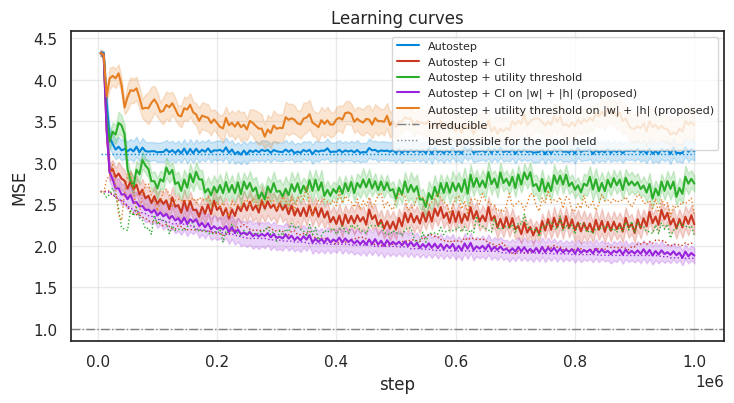

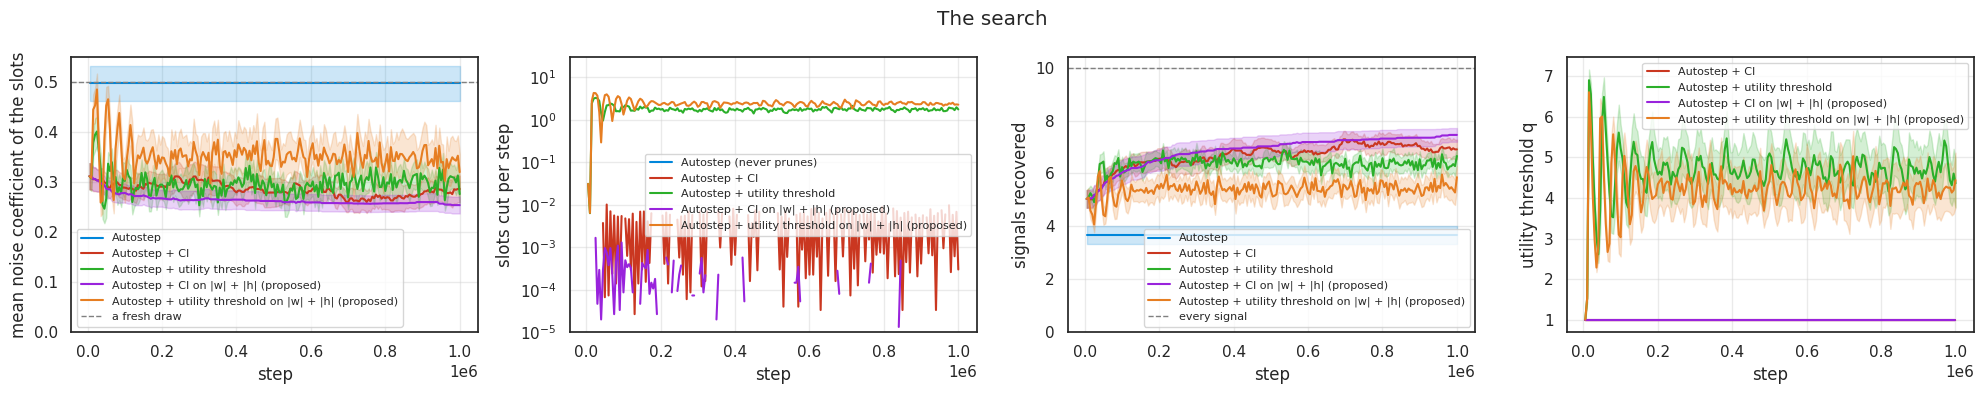

In [ ]:
def plot_curves(methods):
    """MSE per method, mean +- 2 standard errors over seeds, against the floor set by the pool
    each method holds (dotted, in the method's own color)."""
    baseline = IRREDUCIBLE_MSE + N_TARGET_FEATURES * INPUT_VAR   # the mean predictor
    plt.figure(figsize=(7.5, 4.2))
    for (label, res), color in zip(methods.items(), get_color_palette(n=len(methods))):
        mean = res['mse'].mean(0)
        sem = res['mse'].std(0) / np.sqrt(N_SEEDS)
        plt.plot(res['steps'], mean, color=color, label=label)
        plt.fill_between(res['steps'], mean - 2 * sem, mean + 2 * sem, color=color, alpha=0.2)
        floor = IRREDUCIBLE_MSE + (1 - res['recovered']).sum(-1) * INPUT_VAR
        plt.plot(res['steps'], floor.mean(0), color=color, ls=':', lw=1)
    plt.axhline(IRREDUCIBLE_MSE, ls='-.', c='gray', lw=1, label='irreducible')
    plt.plot([], [], c='gray', ls=':', lw=1, label='best possible for the pool held')
    plt.xlabel('step')
    plt.ylabel('MSE')
    plt.ylim(0.85, baseline + 0.25)
    plt.title('Learning curves')
    plt.grid(alpha=0.4)
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


def plot_search(methods):
    """What the sifting does: how clean the pool is, how fast it churns, how much of the signals
    it can recover, and where the bar sits."""
    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    for (label, res), color in zip(methods.items(), get_color_palette(n=len(methods))):
        panels = [(axes[0], res['noise']), (axes[2], res['recovered'].sum(-1))]
        if not np.isnan(res['q']).all():
            panels.append((axes[3], res['q']))
        for ax, series in panels:
            mean = series.mean(0)
            sem = series.std(0) / np.sqrt(N_SEEDS)
            ax.plot(res['steps'], mean, color=color, label=label)
            ax.fill_between(res['steps'], mean - 2 * sem, mean + 2 * sem, color=color, alpha=0.2)

        rate = res['cut_rate'].mean(0)
        if np.any(rate > 0):
            axes[1].plot(res['steps'], np.where(rate > 0, rate, np.nan), color=color, label=label)
        else:
            axes[1].plot([], [], color=color, label=f'{label} (never prunes)')

    axes[0].axhline(0.5, ls='--', c='gray', lw=1, label='a fresh draw')
    axes[0].set_ylabel('mean noise coefficient of the slots')
    axes[0].set_ylim(0, 0.55)
    axes[1].set_ylabel('slots cut per step')
    axes[1].set_yscale('log')
    axes[1].set_ylim(1e-5, 30)
    axes[2].axhline(N_TARGET_FEATURES, ls='--', c='gray', lw=1, label='every signal')
    axes[2].set_ylabel('signals recovered')
    axes[2].set_ylim(0, N_TARGET_FEATURES + 0.4)
    axes[3].set_ylabel('utility threshold q')
    for ax in axes:
        ax.set_xlabel('step')
        ax.grid(alpha=0.4)
        ax.legend(fontsize=8)
    fig.suptitle('The search')
    fig.tight_layout()
    plt.show()


plot_curves(runs)
plot_search(runs)